# P01 — 1-2 POL(P2) 매터링 펌프 "압력 안 걸림" → 펌프 교체 (2026-10-19)

정리본: [`cases/P01.md`](cases/P01.md). 이 노트북은 그 근거를 다시 만든다 (DB·재생은 캐시가 있으면 다시 안 함).

| 단계 | 내용 |
|---|---|
| 1 | 일지 |
| 2 | 그때 경고 이력 (P2·I2) |
| 3 | 고장 구간 원시 신호 — 가동 지령·트립·흡입 압력 스위치·유량·압력 |
| 4 | 재생 (10-01 ~ 10-24) — 일별 피처 추세 |
| 5 | 고정 조건으로 본 저항 — 순환 25 Hz, 같은 SV 자동 사이클 |
| 6 | 고장 전 전조가 있었나 |
| 7 | 고장 중 모델 화면 상태 |

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from review_lib import paths, db, replay, plot
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200)
FIGS = paths.CHECK_DIRS["pump"] / "figs"; FIGS.mkdir(exist_ok=True)
CACHE = paths.CACHE_DIR / "replay" / "p01_P2I2_1001_1024.pkl"
REPLACE = (pd.Timestamp("2026-10-19 06:12"), pd.Timestamp("2026-10-19 06:34"))   # 흡입 압력 스위치 OFF = 라인 개방
TAGS = sorted({"AL_ETC_Bit", "AL_Line_Bit", "AL_MA_Bit", "AL_Tank_Bit", "Auto_Running", "Auto_Running_PL",
               "Hz_Out_P2", "Pump_BuildUp_P2", "Scale_Out___FT_P2", "Scale_Out___PT_P2", "Scale_Out___TT_P5",
               "Shot_Injection_HD1_P2", "g_s_SV_P2", "Hz_Out_I2", "Pump_BuildUp_I2", "Scale_Out___FT_I2",
               "Scale_Out___PT_I2", "Scale_Out___TT_I3", "g_s_SV_I2"})
AUX = ["P00460", "P00302", "P0004A", "P00440", "P00463", "P00441", "Pump_Run_P2",
       "Scale_Out___FT_P2", "Scale_Out___PT_P2", "Hz_Out_P2", "Scale_Out___FT_I2"]

## 1. 일지

In [2]:
acts = pd.read_csv(paths.ACTIONS_DIR / "actions_pump.csv")
acts[acts.incident_id == "P01"][["작업ID", "journal", "start_dt", "end_dt", "설비상세", "조치", "확인메모"]]

,작업ID,journal,start_dt,end_dt,설비상세,조치,확인메모
0,G-01-006,공무반,2026-10-19 06:00:00,2026-10-19 06:50:00,1-2 ST-242 POL 매터링 펌프 압력 안 걸림,펌프 교체,기계실 업무일지에도 유사 작업 기재; 완전 동일 이벤트인지 확인 필요
1,M-01-02-2,기계실,2026-10-19 06:50:00,NaN,발포2라인 1-2POL 펌프 압력안걸림으로 인한 펌프 교체,펌프 교체,공무반에도 유사한 작업 기록 존재; 동일 사건일 가능성 확인 필요


## 2. 그때 경고 이력 (P2·I2)

10-15 로그 시작부터 P2·I2 묶음으로 "헤드 토출 저항 증가"가 떠 있었다. 교체 뒤(10-19 06:51) I2는 빠지고 P2만 남아 "토출 배관 저항 증가"로 바뀐다.

In [3]:
ep = pd.read_csv(paths.EPISODES_DIR / "warning_episodes.csv", parse_dates=["onset", "last_detected", "cleared"])
ep[ep.key.isin(["P2", "I2"]) & (ep.onset < "2026-10-26")][["episode_id", "key", "onset", "last_detected", "reasons", "top_features"]]

,episode_id,key,onset,last_detected,reasons,top_features
0,W0001,P2,2026-10-15 18:58:21.534,2026-10-23 21:14:23.823,pump_head_resistance_high;pump_line_resistance...,P0;pump_resid;r_phys;release_half_sec;ft_cv
1,W0002,I2,2026-10-15 18:58:21.534,2026-10-19 06:51:03.381,pump_head_resistance_high,r_phys;P0;t_self;ft_cv;pump_resid
25,W0026,I2,2026-10-19 14:02:53.946,2026-10-19 17:02:36.888,pump_head_resistance_high,r_phys;ft_cv;P0;release_half_sec;pt_std
28,W0029,I2,2026-10-20 06:58:21.204,2026-10-21 08:03:28.781,pump_head_resistance_high,r_phys;P0;t_self;ft_cv;pump_resid
44,W0045,I2,2026-10-22 08:14:41.568,2026-10-22 08:21:21.156,pump_head_resistance_high,release_half_sec;r_phys;P0;ft_cv;decel_half_sec
52,W0053,I2,2026-10-23 16:56:01.926,2026-10-23 21:14:23.823,pump_head_resistance_high,P0;r_phys;t_self;ft_cv;pump_resid
54,W0055,P2,2026-10-24 06:57:33.924,2026-10-24 23:34:54.577,pump_line_resistance_high;pump_head_resistance...,P0;pump_resid;r_phys;pt_std;release_half_sec
55,W0056,I2,2026-10-24 07:56:22.826,2026-10-24 23:34:54.577,pump_head_resistance_high,r_phys;P0;t_self;ft_cv;pump_resid


## 3. 고장 구간 원시 신호

- `P00460` 인버터 FWD(가동 지령) · `Pump_Run_P2` · `P0004A` 트립 · `P00440` 흡입 압력 스위치 (1 = 정상) — **모델 입력 태그가 아니다.** 여기서만 따로 뽑았다.
- P2 압력은 정지 중 65535(0 밑을 부호 없는 16비트로 읽은 값)라 비운다.

In [4]:
aux = pd.concat([db.fetch_day(d, AUX, group="pump_P2_aux") for d in ["2026-10-18", "2026-10-19"]]).sort_index()
aux["PT_P2"] = aux.Scale_Out___PT_P2.where(aux.Scale_Out___PT_P2 < 60000)
w = aux.loc["2026-10-18 08:20":"2026-10-19 07:00"]
cols = ["P00460", "Pump_Run_P2", "P0004A", "P00440", "Scale_Out___FT_P2", "PT_P2", "Scale_Out___FT_I2"]
w[cols].resample("2min").max().dropna(how="all").query("P00460 > 0 or P00440 < 1")

,P00460,Pump_Run_P2,P0004A,P00440,Scale_Out___FT_P2,PT_P2,Scale_Out___FT_I2
Time,,,,,,,
2026-10-18 08:30:00,1.0,1.0,0.0,1.0,1285.0,92.0,821.0
2026-10-18 08:32:00,1.0,1.0,0.0,1.0,1271.0,85.0,821.0
2026-10-18 08:34:00,1.0,1.0,0.0,1.0,1260.0,90.0,810.0
2026-10-18 08:36:00,1.0,1.0,0.0,1.0,1271.0,92.0,821.0
2026-10-18 08:38:00,1.0,1.0,0.0,1.0,1256.0,89.0,821.0
2026-10-19 05:28:00,1.0,1.0,0.0,1.0,75.0,13.0,821.0
2026-10-19 05:30:00,1.0,1.0,0.0,1.0,74.0,13.0,821.0
2026-10-19 05:32:00,1.0,1.0,0.0,1.0,73.0,13.0,811.0
2026-10-19 05:34:00,1.0,1.0,0.0,1.0,75.0,13.0,809.0


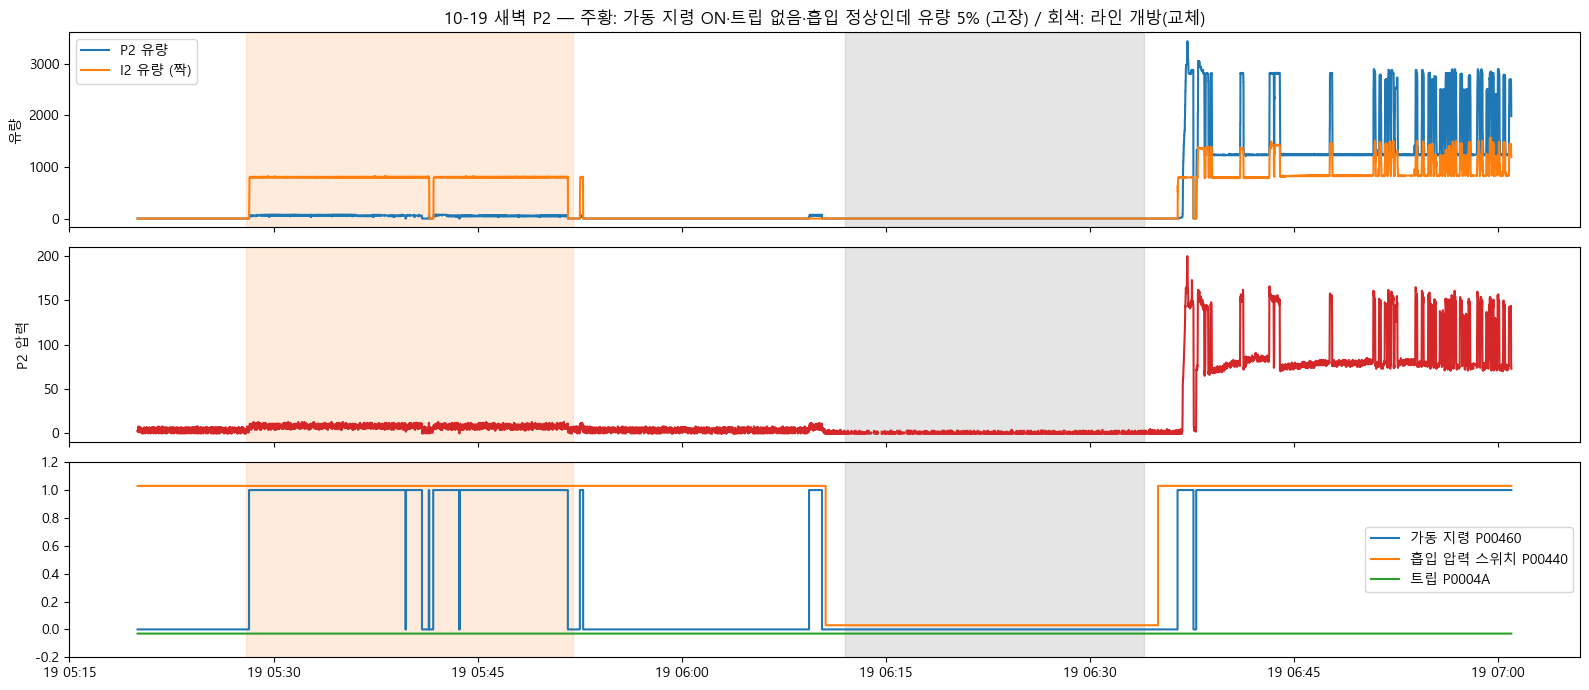

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(16, 7), sharex=True)
seg = aux.loc["2026-10-19 05:20":"2026-10-19 07:00"]
axes[0].plot(seg.index, seg.Scale_Out___FT_P2, label="P2 유량"); axes[0].plot(seg.index, seg.Scale_Out___FT_I2, label="I2 유량 (짝)")
axes[0].set_ylabel("유량"); axes[0].legend(loc="upper left")
axes[1].plot(seg.index, seg.PT_P2, color="tab:red"); axes[1].set_ylabel("P2 압력")
axes[2].step(seg.index, seg.P00460, where="post", label="가동 지령 P00460")
axes[2].step(seg.index, seg.P00440 + 0.03, where="post", label="흡입 압력 스위치 P00440")
axes[2].step(seg.index, seg.P0004A - 0.03, where="post", label="트립 P0004A"); axes[2].legend(loc="center right"); axes[2].set_ylim(-0.2, 1.2)
for ax in axes:
    ax.axvspan(pd.Timestamp("2026-10-19 05:28"), pd.Timestamp("2026-10-19 05:52"), color="tab:orange", alpha=0.15)
    ax.axvspan(*REPLACE, color="tab:gray", alpha=0.2)
axes[0].set_title("10-19 새벽 P2 — 주황: 가동 지령 ON·트립 없음·흡입 정상인데 유량 5% (고장) / 회색: 라인 개방(교체)")
fig.tight_layout(); fig.savefig(FIGS / "P01_failure.png", dpi=110, bbox_inches="tight")

## 4. 재생 (10-01 ~ 10-24) — 일별 피처 추세

운영 펌프 모델에 P2·I2 태그를 흘려 사이클마다 판정·표준화 피처(`zn_*`)·원값(`raw_*`)을 얻는다. 처음 한 번은 약 15분(캐시 저장).

In [6]:
if CACHE.exists():
    C = pd.read_pickle(CACHE)
else:
    parts = []
    for d in pd.date_range("2026-10-01", "2026-10-24"):
        raw = db.fetch_range(d, d + pd.Timedelta(days=1), TAGS, group="pump_HD1_2")
        parts.append(replay.pump_cycles(raw, pumps=["P2", "I2"], progress=False, keep_raw=True))
    C = pd.concat(parts, ignore_index=True)
    C["t"] = pd.to_datetime(C.t_start); C["day"] = (C.t - pd.Timedelta(hours=6)).dt.date
    CACHE.parent.mkdir(parents=True, exist_ok=True); C.to_pickle(CACHE)
A = C[C["mode"] == "자동 운전"]
daily = {}
for p in ["P2", "I2"]:
    daily[p] = A[A.pump == p].groupby("day").agg(
        n=("t", "size"), 알림창비율=("pump_level", lambda s: (s == "알림").mean()),
        PT=("raw_PT", "median"), P0=("raw_P0", "median"), FT_SV=("raw_FT_SV", "median"),
        pump_resid=("raw_pump_resid", "median"), r_phys=("raw_r_phys", "median"),
        z_r=("zn_r_phys", "median"), z_P0=("zn_P0", "median"), z_resid=("zn_pump_resid", "median"))
daily["P2"].round(3)

,n,알림창비율,PT,P0,FT_SV,pump_resid,r_phys,z_r,z_P0,z_resid
day,,,,,,,,,,
2026-10-01,2620,0.000,132.00,65.0,0.993,-0.206,0.998,0.004,0.112,-0.155
2026-10-02,2625,0.000,132.00,65.0,0.991,-0.397,0.996,-0.020,0.112,-0.282
2026-10-03,2953,0.000,132.00,65.0,0.989,-0.486,0.990,-0.081,0.000,-0.345
2026-10-05,2991,0.237,136.00,68.0,0.991,0.598,1.013,0.187,0.375,0.387
2026-10-06,2712,0.609,143.50,73.0,1.004,0.359,1.068,0.748,1.012,0.269
2026-10-07,2743,0.625,145.00,74.0,1.003,0.266,1.076,0.832,1.125,0.190
2026-10-08,2942,0.731,145.00,74.0,1.005,0.353,1.077,0.825,1.125,0.257
2026-10-09,2993,0.707,145.00,73.0,1.005,0.434,1.070,0.765,1.012,0.289
2026-10-10,2832,0.316,142.50,72.0,1.005,0.497,1.062,0.666,1.000,0.306


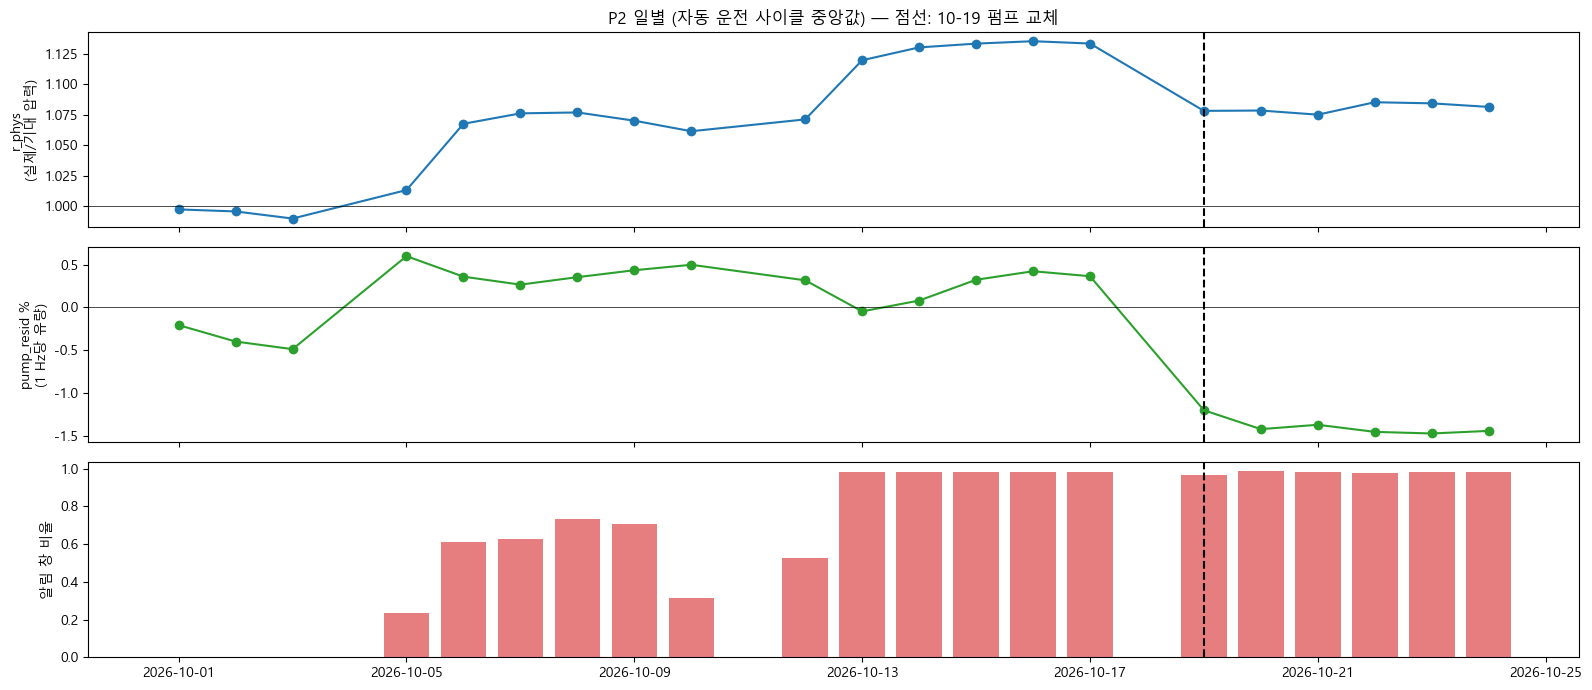

In [7]:
d = daily["P2"]; x = pd.to_datetime(pd.Series(d.index))
fig, axes = plt.subplots(3, 1, figsize=(16, 7), sharex=True)
axes[0].plot(x, d.r_phys.values, "o-"); axes[0].axhline(1, color="k", lw=0.5); axes[0].set_ylabel("r_phys\n(실제/기대 압력)")
axes[1].plot(x, d.pump_resid.values, "o-", color="tab:green"); axes[1].axhline(0, color="k", lw=0.5); axes[1].set_ylabel("pump_resid %\n(1 Hz당 유량)")
axes[2].bar(x, d["알림창비율"].values, color="tab:red", alpha=0.6); axes[2].set_ylabel("알림 창 비율")
for ax in axes:
    ax.axvline(pd.Timestamp("2026-10-19"), color="k", ls="--")
axes[0].set_title("P2 일별 (자동 운전 사이클 중앙값) — 점선: 10-19 펌프 교체")
fig.tight_layout(); fig.savefig(FIGS / "P01_trend.png", dpi=110, bbox_inches="tight")

## 5. 고정 조건으로 본 저항 — 교체가 저항을 바꿨나

`r_phys`는 기대 압력을 **회전수 기준 기대 유량(Hz × r)** 으로 계산한다. 그래서 펌프 토출이 줄면 저항이 그대로여도 `r_phys`가 내려간다.
저항만 보려면 실제 유량으로 나눈 K = PT / FT² 를 같은 조건에서 비교한다.

In [8]:
raw = db.fetch_range("2026-10-01", "2026-10-25", TAGS, group="pump_HD1_2")
r = raw.rename(columns=lambda c: c.replace("Scale_Out___", "").replace("Pump_BuildUp_", "BU_").replace("Hz_Out_", "Hz_"))
hold = r.groupby((r.Hz_P2 != r.Hz_P2.shift()).cumsum()).cumcount()        # 같은 Hz 지령이 이어진 틱 수
circ = r[(r.BU_P2 == 0) & (r.Hz_P2 == 2500) & (r.FT_P2 > 1000) & (r.PT_P2 < 60000) & (hold >= 20)].copy()
circ["day"] = (circ.index - pd.Timedelta(hours=6)).date
circ["K"] = circ.PT_P2 / (circ.FT_P2 / 1000) ** 2
circ.groupby("day").agg(n=("FT_P2", "size"), FT=("FT_P2", "median"), PT=("PT_P2", "median"), K=("K", "median")).round(2)

,n,FT,PT,K
day,,,,
2026-09-30,3,1256.0,66.0,43.11
2026-10-01,44598,1242.0,67.0,43.11
2026-10-02,42973,1241.0,67.0,42.85
2026-10-03,37037,1241.0,67.0,43.50
2026-10-04,6097,1241.0,68.0,44.15
2026-10-05,37813,1244.0,70.0,45.01
2026-10-06,42636,1256.0,76.0,48.18
2026-10-07,44454,1256.0,77.0,49.35
2026-10-08,40977,1256.0,77.0,49.35


In [9]:
# 자동 사이클, 가장 흔한 레시피(SV 3100) 고정
x = A[(A.pump == "P2") & (A.raw_SV_class == 3100)]
x.groupby("day").agg(n=("t", "size"), FT=("raw_FT", "median"), PT=("raw_PT", "median"),
                     K=("raw_K", "median"), FT_Hz=("raw_FT_Hz", "median")).round(3)

,n,FT,PT,K,FT_Hz
day,,,,,
2026-10-01,607,2914.0,137.5,1.617,0.462
2026-10-02,572,2913.0,137.0,1.613,0.462
2026-10-03,798,2907.0,136.0,1.609,0.461
2026-10-05,942,2950.0,141.0,1.621,0.465
2026-10-06,991,2936.0,149.0,1.732,0.463
2026-10-07,998,2928.5,150.0,1.743,0.462
2026-10-08,946,2936.0,150.0,1.740,0.463
2026-10-09,1049,2936.0,149.0,1.729,0.463
2026-10-10,845,2936.0,147.5,1.711,0.463


## 5b. 교체 뒤 1 Hz당 유량이 정말 줄었나 — 검증

위 두 셀은 날짜별 중앙값을 쓴다. 그런데 이 값을 그대로 믿기 전에 확인할 점이 있다.

1. **P2 Hz는 SV에서 고정 환산된다(개루프).** 증압 중 Hz = SV × 환산계수(2850 → 5833, 3100 → 6344)다. 그래서 FT/Hz, FT/SV, `pump_resid`는 사실상 같은 양이다. 서로를 뒷받침하는 독립 증거가 아니다.
2. **유량값은 약 14.5 단위(≈1.2%)로 양자화된다.** 정상 상태에서 1227 / 1241 / 1256만 나온다. 중앙값은 칸 단위로 튀므로 **평균**과 값 분포로 본다.
3. 비교 기간
   - 교체 전: **10-06~17**. 저항이 이미 오른 뒤이고, Hz 환산계수가 교체 후와 같은 구간이다.
   - 교체 후: **10-19~11-12**. 지속 여부를 보려고 11-12까지 늘렸다.
4. 다른 원인을 배제한다: 온도, 압력에 따른 누설(slip), 짝 펌프 I2(공통 원인), 유량계 자체 변화(압력으로 교차 확인).

In [10]:
raw2 = db.fetch_range("2026-10-01", "2026-11-13", TAGS, group="pump_HD1_2")    # 교체 뒤 지속 여부까지 11-12 로 늘린다
r2 = raw2.rename(columns=lambda c: c.replace("Scale_Out___", "").replace("Pump_BuildUp_", "BU_").replace("Hz_Out_", "Hz_"))
r2["day"] = (r2.index - pd.Timedelta(hours=6)).date
def per(df):
    t = df.index
    return np.select([(t >= "2026-10-06") & (t < "2026-10-18"), t >= "2026-10-19 06:40"], ["교체 전 10-06~17", "교체 후 10-19~"], "기타")
# (1) SV → Hz 환산 (증압 중 최빈 Hz). 날짜별로 바뀌면 재보정이 있었다는 뜻
bu = r2[r2.BU_P2 == 1]
hz_map = bu.groupby(["day", "g_s_SV_P2"]).Hz_P2.agg(lambda s: s.mode().iloc[0]).unstack()[[2520, 2850, 3100]]
hz_map.assign(Hz_per_SV=hz_map[2850] / 2850).round(4)

g_s_SV_P2,2520.0,2850.0,3100.0,Hz_per_SV
day,,,,
2026-10-01,5105.0,5801.0,6310.0,2.0354
2026-10-02,5105.0,5801.0,6310.0,2.0354
2026-10-03,5105.0,5801.0,6310.0,2.0354
2026-10-05,5135.0,5833.0,6344.0,2.0467
2026-10-06,5135.0,5833.0,6344.0,2.0467
2026-10-07,5135.0,5833.0,6344.0,2.0467
2026-10-08,5135.0,5833.0,6344.0,2.0467
2026-10-09,5135.0,5833.0,6344.0,2.0467
2026-10-10,5135.0,5833.0,6344.0,2.0467


In [11]:
# (3)(4) 순환 25 Hz — 일별 평균. P2 와 짝 I2, 그리고 P2 유량값 분포(양자화)
def circ(p, tt):
    hz = r2[f"Hz_{p}"]; seg = (hz != hz.shift()).cumsum()
    age = (r2.index.to_series() - r2.index.to_series().groupby(seg.values).transform("min")).dt.total_seconds()
    c = r2[(r2[f"BU_{p}"] == 0) & (hz == 2500) & (age >= 30) & (r2[f"FT_{p}"] > 500) & (r2[f"PT_{p}"] < 60000)]
    o = c.groupby("day").agg(n=(f"FT_{p}", "size"), FT_mean=(f"FT_{p}", "mean"), FT_med=(f"FT_{p}", "median"),
                             PT=(f"PT_{p}", "mean"), TT=(tt, "mean"))
    o["K"] = o.PT / (o.FT_mean / 1000) ** 2
    return o, c
cP2, cP2_ticks = circ("P2", "TT_P5"); cI2, _ = circ("I2", "TT_I3")
display(pd.concat({"P2": cP2, "I2": cI2}, axis=1).round(1))
cP2_ticks = cP2_ticks.assign(per=per(cP2_ticks))
pd.crosstab(cP2_ticks.per, cP2_ticks.FT_P2.astype(int), normalize="index").loc[:, lambda d: d.max() > 0.03].round(3)

P2                                        I2                                  
                n FT_mean  FT_med    PT     TT     K      n FT_mean FT_med    PT     TT     K
day                                                                                          
2026-10-01  27092  1247.1  1241.0  68.7  203.7  44.2  27092   831.2  833.0  35.3  206.2  51.1
2026-10-02  25652  1246.2  1241.0  68.2  207.5  43.9  25651   834.4  833.0  34.6  207.9  49.7
2026-10-03  22838  1242.4  1241.0  68.8  204.4  44.6  22837   843.2  845.0  33.0  206.2  46.5
2026-10-04   6099  1244.8  1241.0  67.8  212.2  43.7   6097   820.8  821.0  34.6  213.1  51.4
2026-10-05  25323  1247.2  1241.0  71.7  203.3  46.1  25321   837.1  833.0  34.9  203.5  49.8
2026-10-06  23864  1250.7  1256.0  78.3  203.0  50.0  23864   833.8  833.0  36.1  203.5  52.0
2026-10-07  26073  1248.8  1243.0  79.7  203.1  51.1  26073   828.2  833.0  36.4  204.3  53.1
2026-10-08  25057  1248.8  1248.0  80.2  203.1  51.4  25057   835.6  833.0  35.7  203.8  51.1
2026-10-09  23979  1250.6  1256.0  79.3  203.1  50.7  23979   838.3  834.0  35.1  203.5  49.9
2026-10-10  25151  1250.8  1256.0  77.7  204.1  49.6  25153   824.6  821.0  36.9  204.6  54.3
2026-10-11   3456  1253.3  1256.0  70.4  264.5  44.8   3455   793.3  796.0  34.6  257.5  55.0
2026-10-12  26127  1247.9  1243.0  78.8  207.9  50.6  26126   824.6  822.0  37.0  205.5  54.4
2026-10-13  24718  1245.5  1241.0  80.1  208.3  51.6  24715   840.7  845.0  34.6  207.2  48.9
2026-10-14  24193  1247.0  1241.0  81.6  204.9  52.5  24192   834.7  833.0  35.6  206.1  51.1
2026-10-15  23404  1249.0  1247.0  82.4  204.5  52.8  23403   825.8  825.0  37.3  204.3  54.7
2026-10-16  22118  1249.5  1256.0  82.9  201.3  53.1  22118   826.4  830.0  37.4  204.3  54.8
2026-10-17  22204  1249.8  1256.0  82.2  205.1  52.6  23059   826.3  827.0  37.4  206.2  54.8
2026-10-18    938  1250.5  1256.0  82.7  190.1  52.9   3603   801.4  797.0  35.2  262.5  54.8
2026-10-19  18554  1232.2  1227.0  78.6  202.7  51.8  18696   830.3  833.0  35.9  203.8  52.1
2026-10-20  23064  1231.5  1227.0  79.4  203.1  52.4  23064   825.3  821.0  37.7  203.2  55.3
2026-10-21  22950  1231.5  1227.0  79.7  203.1  52.5  22950   838.2  845.0  35.6  203.8  50.7
2026-10-22  24698  1231.1  1227.0  79.9  201.8  52.7  24699   840.2  845.0  35.4  203.0  50.1
2026-10-23  26253  1230.9  1227.0  80.2  202.8  52.9  26253   828.0  833.0  37.4  203.5  54.5
2026-10-24  22967  1231.0  1227.0  80.0  203.2  52.8  22965   825.7  832.0  37.6  203.4  55.1
2026-10-25   4473  1235.3  1241.0  69.4  262.3  45.5   4472   814.1  809.0  35.4  251.4  53.4
2026-10-26  23810  1231.5  1227.0  79.7  203.4  52.5  23811   831.0  833.0  36.9  203.1  53.4
2026-10-27  22669  1231.1  1227.0  79.4  203.9  52.4  22669   828.6  833.0  36.7  204.9  53.5
2026-10-28  22470  1230.2  1227.0  80.9  202.9  53.4  22468   829.3  833.0  36.9  204.0  53.6
2026-10-29  24324  1230.7  1227.0  80.2  202.7  52.9  24321   827.2  823.0  37.1  204.3  54.2
2026-10-30  22953  1230.8  1227.0  80.0  204.3  52.8  22953   822.5  821.0  37.6  205.7  55.6
2026-10-31  24099  1231.2  1227.0  79.4  202.1  52.4  24098   825.9  821.0  36.6  203.7  53.6
2026-11-01   6959  1229.5  1227.0  84.1  203.4  55.6   6957   821.3  821.0  36.8  202.8  54.5
2026-11-02  24634  1229.9  1227.0  81.0  202.0  53.5  24634   827.7  832.0  37.3  203.0  54.4
2026-11-03  38391  1230.1  1227.0  80.6  201.7  53.3  38391   826.9  828.0  37.2  203.0  54.4
2026-11-04  40452  1230.0  1227.0  81.1  202.1  53.6  40452   827.6  827.0  37.3  204.2  54.5
2026-11-05  22988  1230.2  1227.0  79.6  202.4  52.6  22988   826.1  822.0  37.2  203.3  54.5
2026-11-06  22681  1230.5  1227.0  79.2  201.2  52.3  22681   826.4  823.0  37.2  201.6  54.5
2026-11-07  16549  1229.2  1227.0  82.3  199.0  54.5  16548   824.1  821.0  37.2  205.0  54.8
2026-11-08   3256  1233.0  1229.0  70.9  254.9  46.6   3254   810.1  808.0  36.0  250.8  54.9
2026-11-09  24419  1230.5  1227.0  78.8  203.8  52.1  24416   828.8

FT_P2,1227,1228,1241,1242,1256
per,,,,,
교체 전 10-06~17,0.000,0.000,0.423,0.019,0.428
교체 후 10-19~,0.689,0.032,0.185,0.010,0.001
기타,0.010,0.000,0.610,0.031,0.243


In [12]:
# (5) 자동 운전 정상 상태 — SV별 일별 1 Hz당 유량 + 교체 전후 요약 + 압력 누설(slip) 점검
b = r2[(r2.BU_P2 == 1) & (r2.Auto_Running == 1)].copy()
b["seg"] = ((r2.BU_P2 != r2.BU_P2.shift()) | (r2.Hz_P2 != r2.Hz_P2.shift())).cumsum().loc[b.index].values
ts = b.index.to_series()
b["age"] = (ts - ts.groupby(b.seg.values).transform("min")).dt.total_seconds().values
b["left"] = (ts.groupby(b.seg.values).transform("max") - ts).dt.total_seconds().values
st = b[(b.age >= 2.5) & (b.left >= 1) & (b.PT_P2 < 60000)]
st = st[(st.FT_P2 / st.groupby("seg").FT_P2.transform("median") - 1).abs() < 0.03].copy()   # 증압 진입·해제 과도 구간 제외
st["FT_Hz"] = st.FT_P2 / (st.Hz_P2 / 100); st["FT_SV"] = st.FT_P2 / st.g_s_SV_P2
st["per"] = per(st)
rows = []
for sv in [2520, 2850, 3100]:
    g = st[st.g_s_SV_P2 == sv].groupby(["per", "day"]).agg(FT_Hz=("FT_Hz", "mean"), FT_SV=("FT_SV", "mean"), PT=("PT_P2", "mean"), TT=("TT_P5", "mean"))
    a, z = g.loc["교체 전 10-06~17"], g.loc["교체 후 10-19~"]
    rows.append(dict(SV=sv, 전_FT_Hz=a.FT_Hz.mean(), 전_일최소=a.FT_Hz.min(), 전_일sd=a.FT_Hz.std(), 후_FT_Hz=z.FT_Hz.mean(), 후_일최대=z.FT_Hz.max(),
                     변화pct=100 * (z.FT_Hz.mean() / a.FT_Hz.mean() - 1), 간격_sd배=(a.FT_Hz.min() - z.FT_Hz.max()) / a.FT_Hz.std(),
                     전_FT_SV=a.FT_SV.mean(), 후_FT_SV=z.FT_SV.mean(), 전_PT=a.PT.mean(), 후_PT=z.PT.mean(), 전_TT=a.TT.mean(), 후_TT=z.TT.mean()))
display(pd.DataFrame(rows).round(3))
# 같은 SV(2850) 교체 전 데이터로 FT/Hz ~ PT + TT 회귀 → 압력 변화가 설명하는 몫
x = st[(st.g_s_SV_P2 == 2850) & (st.per == "교체 전 10-06~17")]
coef = np.linalg.lstsq(np.c_[np.ones(len(x)), x.PT_P2, x.TT_P5], x.FT_Hz, rcond=None)[0]
print(f"FT/Hz 기울기: PT {coef[1]:+.4f}/단위, TT {coef[2]:+.4f}/단위 → 교체 뒤 PT −3.4 는 FT/Hz {-3.4 * coef[1]:+.3f} (반대 방향, 무시할 크기)")
st[st.g_s_SV_P2 == 2850].groupby("day").agg(n=("FT_P2", "size"), FT=("FT_P2", "mean"), FT_Hz=("FT_Hz", "mean"), FT_SV=("FT_SV", "mean"),
                                           PT=("PT_P2", "mean"), TT=("TT_P5", "mean")).round(3)

,SV,전_FT_Hz,전_일최소,전_일sd,후_FT_Hz,후_일최대,변화pct,간격_sd배,전_FT_SV,후_FT_SV,전_PT,후_PT,전_TT,후_TT
0,2520,49.471,49.315,0.07,48.579,48.672,-1.805,9.155,1.008,0.990,126.784,125.251,207.598,207.082
1,2850,49.054,48.870,0.08,48.223,48.328,-1.694,6.814,1.004,0.987,148.083,143.912,207.801,206.665
2,3100,46.151,45.970,0.08,45.385,45.445,-1.660,6.539,0.944,0.929,153.990,150.186,208.138,206.404


FT/Hz 기울기: PT -0.0111/단위, TT +0.0002/단위 → 교체 뒤 PT −3.4 는 FT/Hz +0.038 (반대 방향, 무시할 크기)


,n,FT,FT_Hz,FT_SV,PT,TT
day,,,,,,
2026-10-01,5139,2834.692,48.866,0.995,128.961,204.384
2026-10-02,4201,2830.342,48.791,0.993,128.934,205.727
2026-10-03,4383,2826.405,48.723,0.992,128.436,203.324
2026-10-05,3923,2856.890,49.097,1.002,133.360,207.121
2026-10-06,4163,2865.377,49.124,1.005,143.098,205.883
2026-10-07,3899,2860.424,49.039,1.004,144.978,205.054
2026-10-08,4160,2862.864,49.080,1.005,145.156,206.073
2026-10-09,3105,2865.814,49.131,1.006,144.105,206.754
2026-10-10,3158,2865.713,49.129,1.006,142.773,207.546


**5b 결론 — 교체 뒤 1 Hz당 유량이 줄었다. 사실이다.**

- 크기: 자동 운전 **−1.7%** (SV 2520 −1.81%, 2850 −1.69%, 3100 −1.66%). 순환 25 Hz는 **−1.4%** (평균 1249 → 1231).
  순환 "1256 → 1227 (−2.3%)"는 양자화된 값의 중앙값이 한 칸 반 넘어간 것이라 과장이다.
- 우연이 아니다: 교체 뒤 하루도 빠짐없이 교체 전 12일의 최솟값보다 낮다. 차이는 교체 전 일간 표준편차의 6.5~9배다. 10-19에 계단으로 떨어진 뒤 11-12까지 그대로다. 더 나빠지지도, 회복되지도 않았다.
- 다른 원인으로는 설명되지 않는다.
  - 온도: 교체 전후 같다(208 → 207).
  - 압력에 따른 누설(slip): 교체 뒤 압력이 오히려 낮아서 FT/Hz를 +0.04 (+0.08%) 올리는 쪽이다. 반대 방향이고 크기도 무시할 만하다.
  - 짝 펌프 I2: 순환 유량이 그대로다(825~840, 교체 전과 같은 범위).
  - 유량계만 틀어졌을 가능성: 순환 압력이 따로 떨어졌다. 같은 저항 구간(10-13~17)과 비교하면 81.8 → 79.9 (−2.4%)다. 저항이 그대로일 때 유량 −1.4%에서 기대되는 값(−2.7%)과 비슷하다. 유량계만 문제라면 압력은 그대로였어야 한다.
- **FT/Hz · FT/SV · `pump_resid`는 독립된 세 증거가 아니다.** P2 Hz는 SV에서 고정 환산(×2.0467)되므로 셋이 같은 양이다.
- 재보정: Hz/SV 환산은 10-03 → 10-05에 한 번 바뀌었다(2.0354 → 2.0467, +0.55%). 교체 뒤에는 **11-12까지 바뀌지 않았다.** 그래서 P2는 설정보다 덜 나간다(SV 2850 기준 FT/SV 1.004 → 0.987).
- 원인(새 펌프의 cc/rev 차이인지, 체적 효율 차이인지)은 데이터로 가를 수 없다. 현장 확인이 필요하다.

## 6. 고장 전 전조가 있었나 — 마지막 자동 운전(10-17)까지 2시간 단위

In [13]:
f = ["raw_pump_resid", "raw_FT_SV", "zn_t_self", "zn_decel_half_sec", "zn_release_half_sec", "zn_ft_cv", "score"]
y = A[(A.pump == "P2") & A.t.between("2026-10-15 06:00", "2026-10-18")]
y.groupby(y.t.dt.floor("2h"))[f].median().round(3)

,raw_pump_resid,raw_FT_SV,zn_t_self,zn_decel_half_sec,zn_release_half_sec,zn_ft_cv,score
t,,,,,,,
2026-10-15 06:00:00,0.054,1.002,-0.073,-0.040,0.014,0.025,1.628
2026-10-15 08:00:00,0.095,1.002,0.033,-0.045,-0.018,0.032,1.565
2026-10-15 10:00:00,0.188,1.002,0.096,0.002,-0.032,0.026,1.336
2026-10-15 12:00:00,0.301,1.003,0.091,0.032,0.012,0.003,1.328
2026-10-15 14:00:00,0.303,1.003,-0.075,-0.064,0.037,0.037,1.435
2026-10-15 16:00:00,0.348,1.005,0.027,0.005,-0.023,-0.006,1.347
2026-10-15 18:00:00,0.420,1.005,0.071,0.021,0.024,-0.082,1.170
2026-10-15 20:00:00,0.494,1.005,-0.016,-0.027,0.004,-0.007,1.444
2026-10-15 22:00:00,0.398,1.005,-0.042,-0.051,-0.105,0.001,1.317


## 7. 고장 중 모델 화면 상태

운영 코드(`pump_realtime._tick_state`): 증압 비트가 꺼져 있으면 유량 > `CIRC_MIN_FT`(300)일 때 "대기 순환", 아니면 **"정지"**.
고장 중 유량 58–75 → 화면은 "정지". 자동 사이클이 없으니 판정도 없다. 경고는 10-17 20:15의 "헤드 토출 저항 증가"가 마지막 상태였다.

In [14]:
seg = aux.loc["2026-10-19 05:28":"2026-10-19 05:52"]
state = np.where(seg.Scale_Out___FT_P2 > 300, "대기 순환", "정지")
pd.Series(state).value_counts()

정지    2590
Name: count, dtype: int64